# 사전 준비

In [1]:
import warnings
warnings.filterwarnings('ignore')
import re, os, json
from textwrap import dedent
from pprint import pprint

In [2]:
from langchain_community.document_loaders import TextLoader
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.document_loaders import JSONLoader
from langchain_core.documents import Document
from langchain_text_splitters import CharacterTextSplitter
from langchain_text_splitters import RecursiveCharacterTextSplitter
from transformers import AutoTokenizer
from langchain_openai import OpenAIEmbeddings
from langchain_huggingface.embeddings import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from langchain_core.prompts import PromptTemplate
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from langchain_core.output_parsers import StrOutputParser

In [3]:
from dotenv import load_dotenv
load_dotenv()

True

# 상태 그래프(State Graph)

▶ 상태(state)를 기반으로 작동하는 그래프 구조를 의미한다.   
▶ 복잡한 작업 흐름을 상태와 전이로 모델링하며, 유연하고 제어 가능한 시스템을 구축한다.  
▶ 각 노드(node)가 특정 상태를 나타내며, 엣지(edge)가 상태 간 전이 조건을 정의한다.

<img src="./stateGraph.png" width="1200" align="left" />

# 상태 그래프(State Graph) 구현하기

## 상태(State)를 정의한다.

그래프가 처리하는 데이터의 구조(Schema)를 정의한다.  
LangGraph와 같은 프레임워크에서 상태를 관리할 때 어떤 종류의 데이터가 오고 가는지 명확히 하기 위해 서용된다.

`LangGraph 전반에 걸쳐 공유`되는 상태 `데이터`의 구조를 정의하기 위해서 TypedDict를 import 한다.  
일반적인 딕셔너리는 key에 아무 값이나 넣을 수 있지만, TypedDict를 사용하면 이 딕셔너리에는 `특정 이름의 키가 있어야 하고, 그 값은 특정 타입`이어야 한다라고 엄격하게 제한 할 수 있다.

In [4]:
from typing import TypedDict

TypedDict 클래스를 상속받아 상태 데이터 구조를 정의한다. 이 클래스는 특정한 규칙을 가진 딕셔너리처럼 작동하게 된다.

In [5]:
class MenuState(TypedDict):
    # key: key에 할당될 value의 자료형
    # user_preference라는 key에 할당될 value 값은 반드시 문자열(str) 타입이어야 함을 명시한다.
    user_preference: str # 선호도
    # recommended_menu라는 key에 할당될 value 값은 반드시 문자열(str) 타입이어야 함을 명시한다.
    recommended_menu: str # 추천된 메뉴
    # menu_info라는 key에 할당될 value 값은 반드시 문자열(str) 타입이어야 함을 명시한다.
    menu_info: str # 메뉴 정보

## 노드(Node)를 정의한다.

그래프에서 `실제 작업`을 수행하는 `함수`를 정의한다.  
각 함수는 그래프 전체 상태(MenuState)를 입력받아 특정 작업을 수행하고, 수행된 결과로 `상태의 일부를 업데이트` 한다.

In [6]:
import random

사용자 선호도를 파악하는 노드를 만든다.

In [7]:
def user_preference(state: MenuState) -> MenuState:
    # print('----- 랜덤 사용자 선호도 생성 -----')
    preferences = ['육류', '해산물', '채식', '아무거나']
    # preferences 리스트에 내용 중 한 개를 무작위로 뽑는다.
    # preference = random.sample(preference, k=1)
    preference = random.choice(preferences)
    # print(f'생성된 선호도: {preference}')
    # return을 이용해서 그래프 전체 상태 일부를 업데이트하는 딕셔너리를 리턴시킨다.
    # 딕셔너리의 key 부분에는 상태 클래스에서 선언한 key 값만 사용 가능하다. user_preference라는 key를 preference에 저장된 값으로 업데이트 한다.
    return {'user_preference': preference}

사용자 선호도 기반 메뉴를 선정하는 노드를 만든다.

In [8]:
def recommended_menu(state: MenuState) -> MenuState:
    # print('----- 메뉴 추천 -----')
    # 이전 단계(랜덤 사용자 선호도 생성)에서 저장된 user_preference라는 key에 할당된 값을 가져온다.
    preference = state['user_preference']
    if preference == '육류':
        menu = '스테이크'
    elif preference == '해산물':
        menu = '랍스터'
    elif preference == '채식':
        menu = '그린 샐러드'
    else:
        menu = '쉐프 특선 메뉴'
    # print(f'추천 메뉴: {menu}')
    # return을 이용해서 그래프 전체 상태 일부를 업데이트하는 딕셔너리를 리턴시킨다.
    # 딕셔너리의 key 부분에는 상태 클래스에서 선언한 key 값만 사용 가능하다. recommended_menu라는 key를 menu에 저장된 값으로 업데이트 한다.
    return {'recommended_menu': menu}

선정된 메뉴의 상세 정보를 생성하는 노드를 만든다.

In [9]:
def menu_info(state: MenuState) -> MenuState:
    # print('----- 메뉴 정보 -----')
    # 이전 단계(메뉴 추천)에서 저장된 recommended_menu라는 key에 할당된 값을 가져온다.
    menu = state['recommended_menu']
    if menu == '스테이크':
        info = '스테이크는 두껍게 썬 고기 덩어리를 그릴이나 팬, 오븐 등에 구워낸 요리입니다. 가격: 28,500원'
    elif menu == '랍스터':
        info = '랍스터(바닷가재) 요리는 탱글탱글한 식감과 깊은 감칠맛을 지닌 최고급 해산물 요리입니다. 가격: 35,000원'
    elif menu == '그린 샐러드':
        info = '그린 샐러드는 신선한 녹색 잎채소를 주재료로 하여 가벼운 드레싱과 함께 곁들여 먹는 가장 기초적이고 클래식한 샐러드입니다. 가격: 15,000원'
    else:
        info = '쉐프가 그날그날 엄선한 특별 요리입니다. 가격: 150,000원'
    # print(f'메뉴 정보: {info}')
    # return을 이용해서 그래프 전체 상태 일부를 업데이트하는 딕셔너리를 리턴시킨다.
    # 딕셔너리의 key 부분에는 상태 클래스에서 선언한 key 값만 사용 가능하다. menu_info라는 key를 info에 저장된 값으로 업데이트 한다.
    return {'menu_info': info}

## 그래프(Graph)를 구성한다.

정의한 구성 요소들을 사용하여 전체 그래프를 만든(빌드한)다.

앞서 정의한 노드들을 연결하여 하나의 실행 가능한 워크플로우(Workflow)를 만든다.

그래프의 시작점을 알리는 특별한 기호를 사용하기 위해 START를 import 한다.  
그래프의 끝나는을 알리는 특별한 기호를 사용하기 위해 END를 import 한다.  
노드(작업)와 엣지(연결선)를 담는 전체 그래프 구조를 만들기(설계 도구, Builder) 위해서 StateGraph를 import 한다.  

In [10]:
from langgraph.graph import START, END, StateGraph

C:\miniconda3\envs\AI_LangGraph\Lib\site-packages\langgraph\checkpoint\base\__init__.py:18: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


그래프 설계 도구 객체를 생성한다.

In [11]:
# StateGraph 클래스의 생성자로 TypedDict 클래스를 상속받아 만든 클래스로 LangGraph 전반에 걸쳐 공유되는 상태 데이터를 넘겨서 생성한다.
builder = StateGraph(state_schema=MenuState)

그래프 설계 도구에 노드를 추가한다.

LangGraph에서 노드의 이름과 그래프의 상태 정의(TypedDict 클래스를 상속받아 만든 클래스)에 들어있는 Key와 이름이 중복되지 않게한다.

In [12]:
# add_node() 매소드의 인수로 추가할 노드의 이름과 그래프에서 실제 작업을 수행하는 함수를 넘겨서 노드를 추가한다.
# add_node('노드 이름', 실제 작업을 수행하는 함수 이름)
builder.add_node('user_preference_node', user_preference) # 랜덤 사용자 선호도 생성 노드
builder.add_node('recommended_menu_node', recommended_menu) # 메뉴 추천 노드
builder.add_node('menu_info_node', menu_info) # 메뉴 정보 노드

그래프 설계 도구에 추가된 노드에 엣지(실행 순서)를 추가한다.

In [13]:
# add_edge() 메소드의 인수로 엣지의 출발지와 목적지를 넘겨서 노드끼리 연결해주는 엣지를 추가한다. 화살표를 추가한다.
# add_edge(엣지의 출발지, 엣지의 목적지)
# 프로그램이 '실행'되면(START) '랜덤 사용자 선호도 생성(user_preference_node)' 노드로 가라는 의미이다.
builder.add_edge(START, 'user_preference_node')
# '랜덤 사용자 선호도 생성(user_preference_node)' 노드가 완료되면 '메뉴 추천(recommended_menu_node)' 노드로 가라는 의미이다.
builder.add_edge('user_preference_node', 'recommended_menu_node')
# '메뉴 추천(recommended_menu_node)' 노드가 완료되면 '메뉴 정보(menu_info_node)' 노드로 가라는 의미이다.
builder.add_edge('recommended_menu_node', 'menu_info_node')
# '메뉴 정보(menu_info_node)' 노드가 완료되면 프로그램을 '종료(END)'한다.
builder.add_edge('menu_info_node', END)

그래프 설계 도구를 컴파일해서 실행 가능한 그래프 객체로 만든다.

In [14]:
# compile() 메소드로 컴파일해서 그래프 설계 도구 객체를 완성된 그래프 객체로 만든다.
# 컴파일하면 invoke() 메소드로 그래프를 한 번에 실행할 수 있다.
graph = builder.compile()

설계하고 컴파일한 그래프의 구조를 눈으로 직접 확인할 수 있도록 시각화 한다.

파이썬 대화형 쉘인 IPython(쥬피터 노트북 기반)에서 제공하는 디스플레이 관련 라이브러리를 import 한다.  
이미지 파일 데이터를 파이썬 내에서 이미지 객체로 변환하기 위해 Image를 import 한다.  
텍스트, 그림, 표 등을 화면에 깔끔하게 출력하기 위해 display를 import 한다.  

In [15]:
from IPython.display import Image, display

get_graph() 메소드는 컴파일된 그래프 객체 내부에서 그래프의 논리적 구조(노드와 엣지 정보)를 추출한다.  
draw_mermaid_png() 메소드는 추출된 그래프 구조를 Mermaid.js라는 다이어그램 문법을 사용하여 해석한 뒤, 이를 최종적으로 PNG 이미지 형식으로 렌더링 한다.  
Image 클래스는 방금 생성된 PNG 이미지 데이터를 받아와서, 화면에 뿌릴 수 있는 이미지 객체를 만든다.  
display() 함수는 방금 생성된 이미지 객체를 쥬피터 노트북의 결과 창에 출력한다.

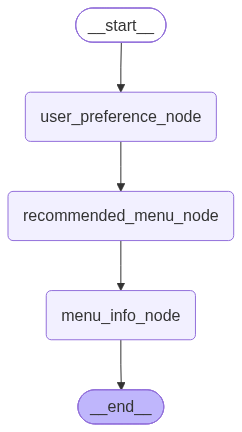

In [16]:
display(Image(graph.get_graph().draw_mermaid_png()))

# 상태 그래프(State Graph) 실행하기

In [17]:
def print_result(result: MenuState):
    print('-' * 100)
    print('선호도: ', result['user_preference'])
    print('추천 메뉴: ', result['recommended_menu'])
    print('메뉴 정보: ', result['menu_info'])
    print('-' * 100)

In [18]:
# 그래프에 입력되는 초기 입력값을 설정한다.
# 첫 번째 노드인 'user_preference_node'는 user_preference() 함수가 무작위로 값을 정해주기 때문에, 지금은 빈 문자열로 초기화만 해서 형식을 맞춘다.
inputs = {'user_preference': ''}

for _ in range(3):
    # invoke() 메소드의 인수로 초기 입력값을 넘겨서 그래프를 실행한다.
    # invoke() 메소드가 실행되면 START 지점에서 시작하여 초기 입력값(inputs)를 가지고 첫 번째 노드(user_preference_node)로 이동한다.
    # 첫 번째 노드로 초기 입력값이 전달되고 무작위로 생성된 사용자 선호도가 MenuState에 저장되고 두 번째 노드(recommended_menu_node)로 이동한다.
    # 두 번째 노드에서 사용자 선호도를 얻어와서 추천 메뉴가 MenuState에 저장되고 세 번째 노드(menu_info_node)로 이동한다.
    # 세 번째 노드에서 추천 메뉴를 얻어와서 메뉴 정보가 MenuState에 저장되고 종료한다.
    result = graph.invoke(inputs)
    print_result(result)

----------------------------------------------------------------------------------------------------
선호도:  육류
추천 메뉴:  스테이크
메뉴 정보:  스테이크는 두껍게 썬 고기 덩어리를 그릴이나 팬, 오븐 등에 구워낸 요리입니다. 가격: 28,500원
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
선호도:  육류
추천 메뉴:  스테이크
메뉴 정보:  스테이크는 두껍게 썬 고기 덩어리를 그릴이나 팬, 오븐 등에 구워낸 요리입니다. 가격: 28,500원
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
선호도:  채식
추천 메뉴:  그린 샐러드
메뉴 정보:  그린 샐러드는 신선한 녹색 잎채소를 주재료로 하여 가벼운 드레싱과 함께 곁들여 먹는 가장 기초적이고 클래식한 샐러드입니다. 가격: 15,000원
----------------------------------------------------------------------------------------------------


# 조건부 엣지 함수로 분기(Branching) 구현하기

엣지는 노드 간의 연결을 정의한다. 조건부 엣지 함수를 사용해서 사용자 입력에 따라서 다른 경로로 진행한다.

▶ 현재 상태나 입력에 따라 다음에 실행할 노드를 동적으로 결정하는 연결이다.  
▶ 시스템의 흐름을 더 유연하고 상황에 맞게 제어하는게 목적이다.  
▶ 조건문을 사용하여 다음에 실행할 노드를 선택한다.

<img src="./edgeBranching.png" width="1200" align="left" />

사용자 입력이 메뉴 추천이면 벡터저장소에서 검색하여 RAG chain을 실행하고, 그렇치 않은 경우에는 LLM이 답변을 생성한다.

## 상태(State)를 정의한다.

그래프에서 공통으로 사용할 데이터의 구조(state schema)를 TypedDict 클래스를 상속받아 정의한다.  
TypedDict는 딕셔너리 형태의 데이터에서 어떤 key가 있어야 하는지와 key에 할당되는 value 값의 타입이 무엇지 고정하는 역할을 한다.

`from typing import TypedDict`

파이썬에서 타입 힌트를 사용할 때, 리스트 내부의 데이터 타입을 명시하기 위해 List를 import 한다.  
파이썬 기본 내장 자료형인 `list`와는 달리 `List`를 사용하면 이 리스트 안에 어떤 종류의 데이터가 들어가는지 대괄호 안에 지정할 수 있다.

In [19]:
from typing import List

In [20]:
class MenuState(TypedDict):
    user_query: str # 사용자 입력
    is_menu: bool # 메뉴 추천과 관련된 질문인가 기억
    # search_results라는 key는 반드시 문자열이 저장된 리스트만 value로 할당할 수 있다.
    search_results: List[str] # 검색 결과
    final_answer: str # 최종 답변

## 사용자 입력이 메뉴 추천이면 사용할 벡터저장소를 불러온다.

벡터화(임베딩)된 데이터를 저장하고 검색하는 벡터저장소를 만들기 위해서 Chroma를 import 한다.  
`from langchain_chroma import Chroma`  
로컬 AI 엔진인 Ollama를 이용해서 텍스트를 숫자의 나열(벡터)로 변환해 주는 임베딩 기능을 사용하기 위해 OllamaEmbeddings을 import 한다.

In [21]:
from langchain_ollama import OllamaEmbeddings

In [22]:
# 불러올 벡터저장소를 생성할 때 사용한 임베딩 모델을 불러온다.
embeddings_model = OllamaEmbeddings(model='bge-m3')

# 메뉴가 저장된 벡터저장소를 불러온다.
menu_db = Chroma(
    embedding_function=embeddings_model,
    collection_name='restaurant_menu',
    persist_directory='./chroma_db'
)
menu_db._collection.count()

10

## 노드(Node)를 정의한다.

LangGraph나 LangChain 시스템에서 각 단계가 수행할 역할을 함수 형태로 만든다. 사용자의 질문을 받고, 분석하고, 검색하여 답변하는 전체 흐름을 정의한다.

`from langchain_core.prompts import ChatPromptTemplate`  
`from langchain_openai import ChatOpenAI`  
`from langchain_core.output_parsers import StrOutputParser`

LangGraph에서 사용할 LLM 모델을 선언한다.

In [23]:
llm = ChatOpenAI(model='gpt-4o-mini')

사용자 질문을 입력받는 노드를 만든다.

In [24]:
def user_query(state: MenuState) -> MenuState:
    query = input('무엇을 도와드릴까요? ')
    # 입력받은 질문으로 상태(user_query)를 업데이트 한다.
    return {'user_query': query}

사용자 질문이 '메뉴 추천'인지 '일반 대화'인지 분석하는 노드를 만든다.

In [25]:
def analyze_input(state: MenuState) -> MenuState:
    # LLM에게 전달할 프롬프트를 만든다.
    template = dedent('''
        입력받은 사용자의 질문을 분석해서 레스토랑 메뉴 추천인지 음식 정보에 관한 질문이지 판단하세요.
        사용자 질문: {user_query}
        레스토랑 메뉴 추천이나 음식 정보에 관련된 질문이면 'True', 아니면 'False'로 답변하세요.
        답변:
    ''')
    prompt = ChatPromptTemplate.from_template(template=template)
    # RAG chain을 만든다.
    rag_chain = prompt | llm | StrOutputParser()
    # RAG chain을 실행한다.
    result = rag_chain.invoke({'user_query': state['user_query']})
    # print(result)
    # RAG chain을 실행한 결과값이 'True' 또는 'true'일 경우 논리값 True로 그 이외의 경우에는 논리값 False로 변환한다.
    result = result.strip().lower() == 'true'
    # 입력받은 질문을 분석한 결과(user_query)를 업데이트 한다.
    return {'is_menu': result}

메뉴 정보를 벡터저장소에서 검색하는 노드를 만든다.

In [26]:
def search_menu_info(state: MenuState) -> MenuState:
    # 벡터저장소에서 유사도 점수가 높은 순으로 상위 문서 2개를 얻어온다.
    results = menu_db.similarity_search(state['user_query'], k=2)
    # 얻어온 문서들(Document 객체)에서 텍스트 내용(page_content)만 뽑아 리스트로 만든다.
    search_results = [doc.page_content for doc in results]
    # 리스트로 만든 결과(search_results)를 업데이트 한다.
    return {'search_results': search_results}

검색된 메뉴 정보에 대한 답변을 생성하는 노드를 만든다.

In [27]:
def menu_response(state: MenuState) -> MenuState:
    # search_menu_info_node에서 검색한 결과를 활용하도록 지시하는 프롬프트를 만든다.
    template = dedent('''
        아래의 사용자 입력과 사용자 입력을 벡터저장소에서 검색한 메뉴 관련 검색 결과를 바탕으로 사용자의 메뉴 관련 질문에 대한 상세한 답변을 생성하세요.
        사용자 입력: {user_query}
        메뉴 관련 검색 결과: {search_results}
        검색 결과의 정보를 활용하여 정확하고 유용한 정보를 제공하세요.
        답변:
    ''')
    prompt = ChatPromptTemplate.from_template(template=template)
    # RAG chain을 만든다.
    rag_chain = prompt | llm | StrOutputParser()
    # RAG chain을 실행한다.
    result = rag_chain.invoke({
        'user_query': state['user_query'], 
        'search_results': state['search_results']
    })
    # 메뉴 정보에 대해 생성된 최종 답변을 출력한다.
    print(f'메뉴 정보:\n{result}')
    print('-' * 100)
    # 최종 답변(final_answer)을 업데이트 한다.
    return {'final_answer': result}

메뉴 정보와 관련없는 일반 답변을 생성하는 노드를 만든다.

In [28]:
def general_response(state: MenuState) -> MenuState:
    # 메뉴와 관련 없음을 인지시키고 일반 대화를 유도하는 프롬프트를 만든다.
    template = dedent('''
        사용자 입력: {user_query}
        위의 사용자 입력은 레스토랑 메뉴나 음식 정보와 전혀 관련이 없습니다.
        일반적인 대화 맥락에서 적절한 답변을 생성하세요.
        답변:
    ''')
    prompt = ChatPromptTemplate.from_template(template=template)
    # RAG chain을 만든다.
    rag_chain = prompt | llm | StrOutputParser()
    # RAG chain을 실행한다.
    result = rag_chain.invoke({'user_query': state['user_query']})
    # 메뉴 정보와 관련 없는 일반 답변을 최종 답변으로 출력한다.
    print(f'일반 정보:\n{result}')
    print('-' * 100)
    # 최종 답변(final_answer)을 업데이트 한다.
    return {'final_answer': result}

## 조건부 엣지 함수를 만든다.

이 함수는 `analyze_input_node` 노드에서 분석한 결과에 따라서 어떤 노드로 이동할 지 판단하는 역할을 하고 그래프에 노드로 추가할 필요 없으므로 그래프를 출력하면 조건부 엣지 노드는 나타나지 않는다.

함수가 리턴할 수 있는 값을 특정 문자열로 제한하기 위해서 Literal를 import 한다.

In [29]:
from typing import Literal

Literal['search_menu_info_node', 'general_response_node']는 이 함수는 'search_menu_info_node' 또는 'general_response_node'라는 두 가지 문자열 중 하나를 반환해야 함을 명시해서 오타 방지와 코드 안정성을 위한 장치이다.

In [30]:
def conditional_edge(state: MenuState) -> Literal['search_menu_info_node', 'general_response_node']:
    if bool(state['is_menu']):
        # 메뉴 관련 질문일 경우 분기할 노드를 리턴시킨다.
        # analyze_input_node에서 판단한 is_menu라는 key에 할당된 value가 True 라면?
        # 메뉴 정보에 대한 답변을 생성하기 위해 메뉴 정보를 찾아오는 search_menu_info_node로 이동하라고 명령한다.
        return 'search_menu_info_node'
    else:
        # 메뉴와 관련 없는 질문일 경우 분기할 노드를 리턴시킨다.
        # analyze_input_node에서 판단한 is_menu라는 key에 할당된 value가 False 라면?
        # 일반 정보에 대한 답변을 생성하기 위해 general_response_node로 이동하라고 명령한다.
        return 'general_response_node'

## 그래프(Graph)를 구성한다.

`from langgraph.graph import START, END, StateGraph`

그래프 설계 도구 객체를 생성한다.

In [31]:
builder = StateGraph(state_schema=MenuState)

노드를 추가한다.

In [32]:
builder.add_node('user_query_node', user_query) # 사용자 질문을 입력받는 노드
builder.add_node('analyze_input_node', analyze_input) # 사용자 질문을 분석하는 노드

# 메뉴 정보에 대한 답변을 생성하는 노드
builder.add_node('search_menu_info_node', search_menu_info) # 벡터저장소에서 메뉴 정보를 검색하는 노드
builder.add_node('menu_response_node', menu_response) # 메뉴 정보에 대한 답변을 생성하는 노드

# 일반 정보에 대한 답변을 생성하는 노드
builder.add_node('general_response_node', general_response) # 일반 답변을 생성하는 노드

엣지를 추가한다.

In [33]:
# 고정 엣지를 설정한다.
builder.add_edge(START, 'user_query_node') # 그래프가 시작되면 user_query_node를 실행한다.
builder.add_edge('user_query_node', 'analyze_input_node') # 사용자 질문을 받았으면 analyze_input_node를 실행한다.

# 조건부 엣지를 설정한다.
# add_conditional_edges() 메소드의 인수로 분기되기 전 실행할 마지막 노드, 조건부 엣지 함수, 딕셔너리로 분기할 노드 정보를 넘겨서 조건부 엣지를 설정한다.
builder.add_conditional_edges(
    # 분기되기 전 실행할 마지막 노드를 설정한다. 조건부 분기가 시작되는 출발지 노드를 설정한다.
    source='analyze_input_node',
    # 조건부 엣지 함수를 설정한다. 조건부 엣지 함수의 실행 결과에 따라서 analyze_input_node 다음에 어떤 노드로 이동할지 판단한다.
    path=conditional_edge,
    # 조건부 엣지 함수가 리턴하는 값과 실제 실행할 그래프의 노드 이름을 연결(매핑)해주는 딕서너리를 설정한다.
    path_map={
        # ':' 왼쪽은 조건부 엣지 함수의 리턴값이고 오른쪽은 실제 이동할 노드 이름이다.
        # conditional_edge 함수가 실행된 결과로 'search_menu_info_node'라는 문자열을 리턴했다면 그래프 흐름을 'search_menu_info_node'로 이동시키라는 의미이다.
        'search_menu_info_node': 'search_menu_info_node',
        # conditional_edge 함수가 실행된 결과로 'general_response_node'라는 문자열을 리턴했다면 그래프 흐름을 'general_response_node'로 이동시키라는 의미이다.
        'general_response_node': 'general_response_node'
    }
)

# 메뉴 정보에 대한 답변을 생성하는 노드들을 엣지로 연결한다.
# builder.add_edge('analyze_input_node', 'search_menu_info_node') # 사용자 질문으로 메뉴 정보를 검색하는 search_menu_info_node를 실행한다.
builder.add_edge('search_menu_info_node', 'menu_response_node') # 메뉴 정보에 대한 답변을 생성하는 menu_response_node를 실행한다.
builder.add_edge('menu_response_node', END) # menu_response_node를 실행했으면 그래프를 종료한다.

# 메뉴 정보와 관련없는 일반 답변을 생성하는 노드들을 엣지로 연결한다.
# builder.add_edge('analyze_input_node', 'general_response_node') # 메뉴 정보에 대한 답변을 생성하는 'general_response_node'를 실행한다.
builder.add_edge('general_response_node', END) # general_response_node를 실행했으면 그래프를 종료한다.

컴파일한다.

In [34]:
graph = builder.compile()

`from IPython.display import Image, display`

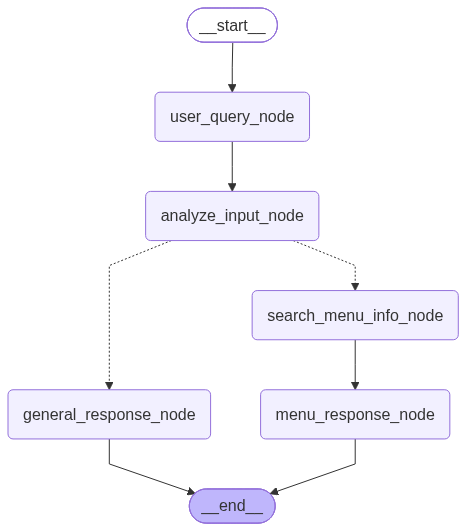

In [35]:
display(Image(graph.get_graph().draw_mermaid_png()))

## 그래프 실행하기

In [ ]:
# 그래프에 입력되는 초기 입력값을 설정한다.
# 실제 질문은 그래프 내부의 첫 번째 노드인 'user_query_node'에서 입력받기 때문에, 지금은 빈 문자열로 초기화만 해서 형식을 맞춘다.
inputs = {'user_query': ''}

result = graph.invoke(inputs)
result

In [36]:
while True:
    inputs = {'user_query': ''}
    graph.invoke(inputs)
    condition = input('다른 질문이 있나요?(y/n): ').lower()
    if condition == 'n':
        print('대화를 종료합니다. 바이바이~~~~~')
        break

무엇을 도와드릴까요? 샐러드 메뉴의 가격은 얼마인가요?
메뉴 정보:
샐러드 메뉴의 가격은 다음과 같습니다:

1. **가든 샐러드** - 가격: **₩12,000**
   - 주요 식재료: 유기농 믹스 그린, 체리 토마토, 오이, 당근, 발사믹 드레싱
   - 설명: 신선한 유기농 채소로 구성된 건강한 샐러드로, 아삭한 식감의 믹스 그린과 달콤한 체리 토마토, 오이, 당근이 어우러져 다양한 맛과 식감을 즐길 수 있습니다. 특제 발사믹 드레싱이 채소 본연의 맛을 살려줍니다.

2. **안심 스테이크 샐러드** - 가격: **₩26,000**
   - 주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈
   - 설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.

두 가지 샐러드 중 선택하실 수 있으며, 각각의 특색 있는 맛과 신선함을 느껴보실 수 있습니다!
----------------------------------------------------------------------------------------------------
다른 질문이 있나요?(y/n): y
무엇을 도와드릴까요? 대한민국의 대표 관광지 3곳을 알려주세요?
일반 정보:
대한민국의 대표 관광지 3곳은 다음과 같습니다:

1. **경복궁**: 서울에 위치한 조선시대의 대표적인 궁궐로, 아름다운 전통 건축과 역사적인 유물이 많아 많은 관광객들이 찾는 명소입니다. 특히 국립민속박물관과 광화문, 그리고 경복궁의 아름다운 정원은 놓칠 수 없는 포인트입니다.

2. **제주도**: 한국의 대표적인 휴양지로, 아름다운 자연과 독특한 문화가 함께 어우러진 곳입니다. 한라산, 성산일출봉, 만장굴 등의 다양한 자연 경관과 함께 여러 가지 해양 액티비티를 즐길 수 있습니다.

3. **부산 해운대**: 부산의 상징적인 해변으로,